## Assignment -11-

**Scaling Machine Learning with PySpark: Sensorless Drive Diagnosis**

## Context & Scenario
You are an ML systems engineer at a manufacturing analytics firm supporting a predictive-maintenance team. The organization wants a scalable multiclass classification workflow that can run locally during development and transfer cleanly to a Spark cluster for larger retraining jobs. Your task is to build and justify a reproducible PySpark pipeline for diagnosing motor operating conditions from sensor-derived features. The project must balance predictive quality with operational concerns such as validation, monitoring, drift detection, cost, and rollback readiness.

## Dataset
- **Dataset name:** UCI Dataset for Sensorless Drive Diagnosis
- **Access links:**
  - https://archive.ics.uci.edu/dataset/325/dataset+for+sensorless+drive+diagnosis
  - https://archive.ics.uci.edu/static/public/325/dataset+for+sensorless+drive+diagnosis.zip
- The dataset contains approximately **58,509 observations** and **48 continuous input features** extracted from electric current drive signals, plus a multiclass target with **11 operating-condition classes**. The unit of analysis is one labeled sensor-derived observation used for fault/condition diagnosis. Its size and numeric feature structure make it appropriate for Spark-based ingestion, preprocessing, and comparative modeling.


## Machine Learning Tasks
- Load the dataset into a Spark DataFrame and document the ingestion path and resulting schema.
- Apply validation guardrails for schema consistency, label range, missing values, duplicates, and basic numeric sanity checks.
- Conduct concise EDA: class balance, summary statistics, one representative feature distribution, and a small correlation or relationship summary.
- Build preprocessing with `VectorAssembler` and **feature scaling**; include an **optional justified transform** only if appropriate.
- Compare at least two models: a reproducible baseline and a stronger tuned candidate for multiclass prediction.
- Evaluate and interpret held-out performance using appropriate multiclass metrics and diagnostic summaries, not metrics alone.
- Discuss ML-systems considerations: experiment reproducibility, monitoring signals, drift risks, computational cost, and when rollback would be warranted.

## Deliverables
- One executed Jupyter notebook with code, outputs, and concise written interpretations.
- A brief model-comparison summary reporting validation checks, final metrics, and key error patterns.
- A short systems note describing reproducibility choices, monitoring/drift plan, and deployment tradeoffs.

## Grading Rubric (100 points)
| Category | Points | Full-credit criteria |
|---|---:|---|
| Code correctness | 20 | Notebook runs in order; Spark APIs, pipelines, and evaluation are implemented correctly. |
| Data quality / validation | 15 | Guardrails are appropriate, clearly reported, and used to justify training readiness. |
| EDA | 15 | EDA is relevant, concise, and supports later preprocessing or modeling decisions. |
| Modeling / evaluation | 25 | Baseline and comparison model are appropriate; evaluation uses sound multiclass metrics and diagnostics. |
| Interpretation | 10 | Conclusions accurately explain performance, error structure, and practical limitations. |
| ML-systems thinking | 15 | Work addresses reproducibility, monitoring, drift, compute/latency cost, and rollback criteria with clear reasoning. |


____________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________

# Assignment 11: Scaling Machine Learning with PySpark

In [1]:
import os
import zipfile
import urllib.request
import time

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pyspark.sql import SparkSession
from pyspark.sql.functions import (
    col, trim, split, count, isnan, when, abs
)
from pyspark.sql.types import DoubleType

from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.classification import (
    LogisticRegression,
    RandomForestClassifier
)
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
from pyspark.ml.tuning import ParamGridBuilder, TrainValidationSplit

RANDOM_STATE = 42

spark = (
    SparkSession.builder
    .appName("SensorlessDriveDiagnosis")
    .master("local[2]")
    .config("spark.driver.memory", "4g")
    .config("spark.sql.shuffle.partitions", "4")
    .config("spark.default.parallelism", "2")
    .getOrCreate()
)

print("Spark version:", spark.version)
print("Spark application:", spark.sparkContext.applicationId)
print("Spark session started successfully.")

Spark version: 4.3.0
Spark application: local-1793931372379
Spark session started successfully.


The Spark session runs locally using the available CPU cores. A fixed random seed and a consistent Spark configuration help make the experiment reproducible. The same pipeline structure can later be used on a Spark cluster by changing the execution configuration.

## Dataset Ingestion

The dataset comes from the UCI Sensorless Drive Diagnosis collection. It contains 48 continuous sensor-derived features and one target column representing the operating condition. The downloaded file contains whitespace-separated numeric values, so the data is parsed into Spark columns before modeling.

In [3]:
DATA_URL = (
    "https://archive.ics.uci.edu/static/public/325/"
    "dataset+for+sensorless+drive+diagnosis.zip"
)

ZIP_PATH = "sensorless_drive_diagnosis.zip"
EXTRACT_FOLDER = "sensorless_drive_data"

if not os.path.exists(ZIP_PATH):
    urllib.request.urlretrieve(DATA_URL, ZIP_PATH)
    print("Dataset downloaded.")

if not os.path.exists(EXTRACT_FOLDER):
    os.makedirs(EXTRACT_FOLDER)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_FOLDER)

print("Dataset extracted.")

Dataset extracted.


In [4]:
data_file = None

for root, dirs, files in os.walk(EXTRACT_FOLDER):
    for file in files:
        if file.lower().endswith(".txt"):
            data_file = os.path.join(root, file)
            break
    if data_file is not None:
        break

if data_file is None:
    raise FileNotFoundError("Could not find the dataset text file.")

print("Dataset file:", data_file)

Dataset file: sensorless_drive_data\Sensorless_drive_diagnosis.txt


In [5]:
raw_df = spark.read.text(data_file)

# Remove blank lines and split each row using whitespace.
split_df = raw_df.filter(trim(col("value")) != "").select(
    split(trim(col("value")), r"\s+").alias("values")
)

# The dataset has 48 features and one target column.
feature_names = [f"feature_{i:02d}" for i in range(1, 49)]
all_names = feature_names + ["label"]

df = split_df.select(
    *[
        col("values").getItem(i).cast(DoubleType()).alias(name)
        for i, name in enumerate(all_names)
    ]
)

print("Dataset rows:", df.count())
print("Dataset columns:", len(df.columns))
df.printSchema()
df.show(5)

Dataset rows: 58509
Dataset columns: 49
root
 |-- feature_01: double (nullable = true)
 |-- feature_02: double (nullable = true)
 |-- feature_03: double (nullable = true)
 |-- feature_04: double (nullable = true)
 |-- feature_05: double (nullable = true)
 |-- feature_06: double (nullable = true)
 |-- feature_07: double (nullable = true)
 |-- feature_08: double (nullable = true)
 |-- feature_09: double (nullable = true)
 |-- feature_10: double (nullable = true)
 |-- feature_11: double (nullable = true)
 |-- feature_12: double (nullable = true)
 |-- feature_13: double (nullable = true)
 |-- feature_14: double (nullable = true)
 |-- feature_15: double (nullable = true)
 |-- feature_16: double (nullable = true)
 |-- feature_17: double (nullable = true)
 |-- feature_18: double (nullable = true)
 |-- feature_19: double (nullable = true)
 |-- feature_20: double (nullable = true)
 |-- feature_21: double (nullable = true)
 |-- feature_22: double (nullable = true)
 |-- feature_23: double (nullab

The data is loaded directly into a Spark DataFrame instead of being processed entirely with pandas. This keeps the ingestion and modeling workflow within Spark. The expected structure is 48 numeric input features and one numeric class label.

## Data Quality and Validation

Before training, the dataset is checked for the expected number of columns, missing or invalid values, duplicate observations, and valid target labels. These checks help prevent malformed data from entering the training pipeline.

In [6]:
# Check the expected schema.
assert len(feature_names) == 48
assert len(df.columns) == 49
assert all(field.dataType == DoubleType() for field in df.schema.fields)

print("Schema check passed.")

Schema check passed.


In [7]:
row_count = df.count()

# Count null and NaN values in each column.
missing_counts = {}

for name in df.columns:
    missing_count = df.filter(
        col(name).isNull() | isnan(col(name))
    ).count()

    missing_counts[name] = missing_count

missing_df = pd.DataFrame(
    list(missing_counts.items()),
    columns=["Column", "Missing Values"]
)

print("Total rows:", row_count)
print("Columns with missing values:")
print(missing_df[missing_df["Missing Values"] > 0])

Total rows: 58509
Columns with missing values:
Empty DataFrame
Columns: [Column, Missing Values]
Index: []


In [8]:
# Check duplicate observations.
duplicate_count = row_count - df.dropDuplicates().count()

print("Duplicate rows:", duplicate_count)

# Check target label values.
print("Target label values:")
df.groupBy("label").count().orderBy("label").show(20)

Duplicate rows: 0
Target label values:
+-----+-----+
|label|count|
+-----+-----+
|  1.0| 5319|
|  2.0| 5319|
|  3.0| 5319|
|  4.0| 5319|
|  5.0| 5319|
|  6.0| 5319|
|  7.0| 5319|
|  8.0| 5319|
|  9.0| 5319|
| 10.0| 5319|
| 11.0| 5319|
+-----+-----+



In [9]:
# Check that labels are within the expected range of 1 through 11.
label_values = [
    row["label"]
    for row in df.select("label").distinct().collect()
]

assert set(label_values) == set(range(1, 12)), \
    "Unexpected or missing target classes."

# Check for missing and invalid numeric values.
invalid_numeric_count = 0

for name in df.columns:
    invalid_numeric_count += df.filter(
        col(name).isNull() |
        isnan(col(name)) |
        (abs(col(name)) > 1000000)
    ).count()

assert invalid_numeric_count == 0, \
    "Missing, NaN, or unexpectedly large numeric values found."

assert row_count > 50000, "Dataset contains unexpectedly few rows."

print("All validation guardrails passed.")

All validation guardrails passed.


The validation checks confirm that the dataset has the expected 49 columns and all 11 target classes. The checks also verify that there are no missing or invalid numeric values and that the dataset contains the expected general number of observations. Duplicate rows are counted separately because repeated sensor measurements may need investigation before production use.

## Exploratory Data Analysis

The EDA examines the distribution of the operating-condition classes, feature summary statistics, and relationships between selected sensor features. This helps identify class imbalance, unusual values, and potentially related measurements before modeling.

+-----+-----+
|label|count|
+-----+-----+
|  1.0| 5319|
|  2.0| 5319|
|  3.0| 5319|
|  4.0| 5319|
|  5.0| 5319|
|  6.0| 5319|
|  7.0| 5319|
|  8.0| 5319|
|  9.0| 5319|
| 10.0| 5319|
| 11.0| 5319|
+-----+-----+



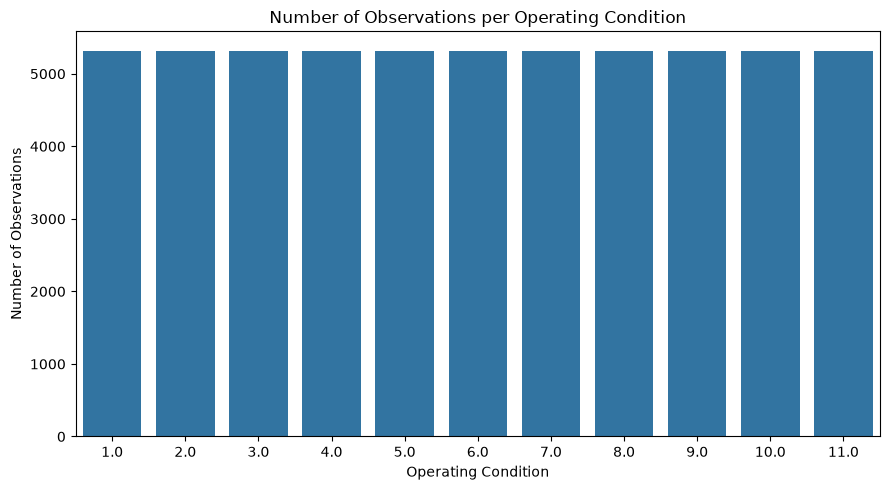

In [10]:
# Class balance.
class_balance = (
    df.groupBy("label")
    .count()
    .orderBy("label")
)

class_balance.show()

class_balance_pd = class_balance.toPandas()

plt.figure(figsize=(9, 5))
sns.barplot(
    data=class_balance_pd,
    x="label",
    y="count"
)
plt.title("Number of Observations per Operating Condition")
plt.xlabel("Operating Condition")
plt.ylabel("Number of Observations")
plt.tight_layout()
plt.show()

In [11]:
# Summary statistics for the sensor features.
df.select(feature_names).describe().show()

+-------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+------------------+------------------+------------------+------------------+-------------------+------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+------------------+-----------------+-------------------+------------------+-----------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+
|sum

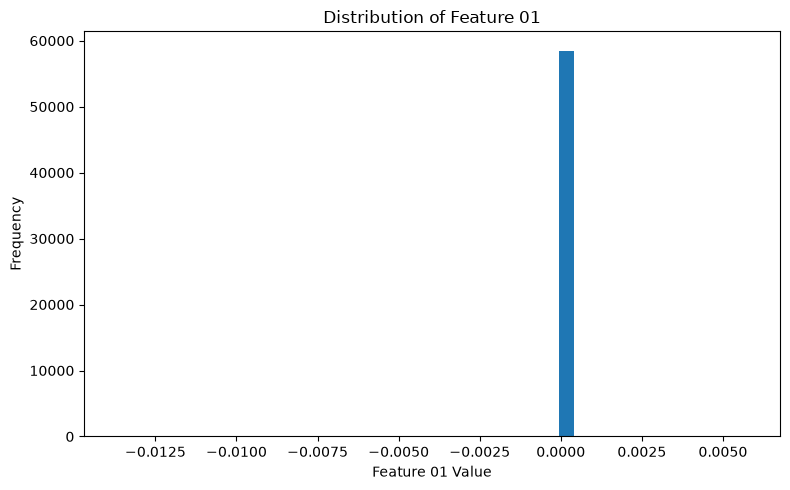

In [12]:
# Display the distribution of one representative feature.
feature_pd = df.select("feature_01").toPandas()

plt.figure(figsize=(8, 5))
plt.hist(feature_pd["feature_01"], bins=40)
plt.title("Distribution of Feature 01")
plt.xlabel("Feature 01 Value")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

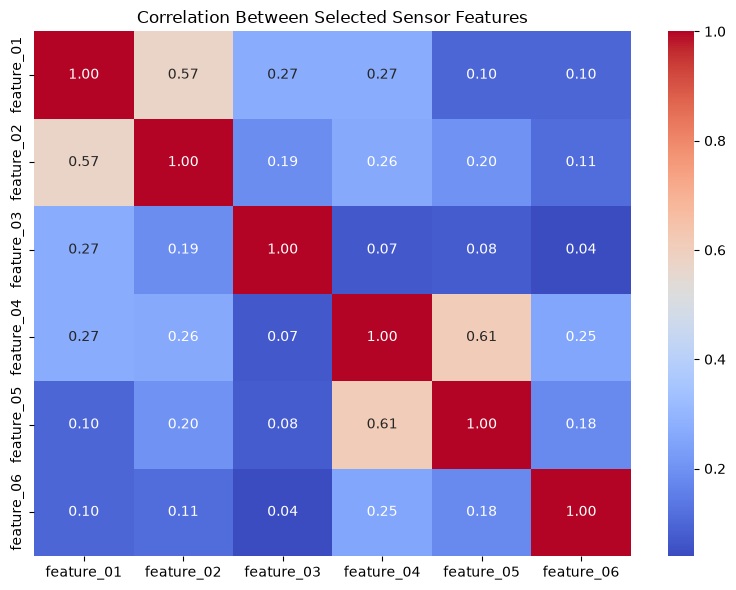

In [13]:
# Calculate correlations for a small selection of features.
correlation_features = [
    "feature_01",
    "feature_02",
    "feature_03",
    "feature_04",
    "feature_05",
    "feature_06"
]

correlation_pd = df.select(correlation_features).toPandas()
correlation_matrix = correlation_pd.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Between Selected Sensor Features")
plt.tight_layout()
plt.show()

The class balance plot shows how observations are distributed across the 11 operating conditions. The summary statistics and feature distribution help identify the scale and spread of the sensor measurements. The correlation heatmap provides a small view of how selected features move in relation to one another. Since the features are continuous measurements, scaling is appropriate before fitting Logistic Regression.

## Preprocessing and Data Splitting

The target label is converted from values 1 through 11 to values 0 through 10 because Spark's multiclass classifiers expect class indices starting at zero. The data is split into training and testing sets using a fixed random seed. The test set is held out for the final evaluation.

In [14]:
from pyspark.sql.functions import monotonically_increasing_id

# Convert labels 1-11 into class indices 0-10.
model_df = df.withColumn("label", col("label").cast("double") - 1)

# Confirm the converted labels.
model_df.groupBy("label").count().orderBy("label").show()

# Reproducible 80/20 split.
train_df, test_df = model_df.randomSplit(
    [0.80, 0.20],
    seed=RANDOM_STATE
)

print("Training rows:", train_df.count())
print("Testing rows:", test_df.count())

+-----+-----+
|label|count|
+-----+-----+
|  0.0| 5319|
|  1.0| 5319|
|  2.0| 5319|
|  3.0| 5319|
|  4.0| 5319|
|  5.0| 5319|
|  6.0| 5319|
|  7.0| 5319|
|  8.0| 5319|
|  9.0| 5319|
| 10.0| 5319|
+-----+-----+

Training rows: 46920
Testing rows: 11589


In [15]:
# Confirm that both datasets contain all 11 classes.
train_classes = {
    row["label"] for row in train_df.select("label").distinct().collect()
}

test_classes = {
    row["label"] for row in test_df.select("label").distinct().collect()
}

assert len(train_classes) == 11, "Training data is missing a class."
assert len(test_classes) == 11, "Test data is missing a class."

print("Training and testing class checks passed.")

Training and testing class checks passed.


The split keeps approximately 80 percent of the observations for training and 20 percent for testing. The class checks make sure that all operating conditions are represented in both sets. A fixed seed makes the split repeatable, although a random split does not guarantee exactly equal class proportions in each set.

## Feature Assembly and Scaling

VectorAssembler combines the 48 sensor columns into a single feature vector. StandardScaler standardizes the feature values for Logistic Regression, where differences in feature ranges can affect model fitting. Random Forest uses the assembled features without scaling because tree-based models do not require standardized input values. Both models use the same original sensor features and training/testing split.

In [16]:
assembler = VectorAssembler(
    inputCols=feature_names,
    outputCol="assembled_features"
)

scaler = StandardScaler(
    inputCol="assembled_features",
    outputCol="features",
    withStd=True,
    withMean=True
)

print("Feature assembler and scaler created.")

Feature assembler and scaler created.


## Baseline Model: Logistic Regression

Multinomial Logistic Regression is used as the baseline because it is a relatively simple and interpretable classifier. It provides a useful reference point for determining whether a more complex model improves multiclass prediction.

In [17]:
logistic = LogisticRegression(
    featuresCol="features",
    labelCol="label",
    maxIter=100,
    regParam=0.01,
    family="multinomial"
)

logistic_pipeline = Pipeline(
    stages=[assembler, scaler, logistic]
)

start_time = time.time()

logistic_model = logistic_pipeline.fit(train_df)

logistic_training_time = time.time() - start_time

print("Logistic Regression training time:",
      round(logistic_training_time, 2), "seconds")

Logistic Regression training time: 4.77 seconds


## Comparison Model: Random Forest

Random Forest was selected as the comparison model because it can capture nonlinear relationships and interactions between sensor features. A smaller configuration with 20 trees and a maximum depth of 6 was used after reducing the computational workload during model training. The model was evaluated using the same held-out test dataset as Logistic Regression.

In [23]:
# Train the Random Forest model.

# Identify the 48 input feature columns.
feature_cols = [
    column for column in train_df.columns
    if column.startswith("feature_")
]

print("Number of input features:", len(feature_cols))

# Combine the feature columns into a vector.
rf_assembler = VectorAssembler(
    inputCols=feature_cols,
    outputCol="features"
)

# Configure the Random Forest.
rf = RandomForestClassifier(
    featuresCol="features",
    labelCol="label",
    numTrees=20,
    maxDepth=6,
    maxBins=32,
    seed=RANDOM_STATE
)

# Create the pipeline.
rf_pipeline = Pipeline(
    stages=[rf_assembler, rf]
)

# Train the model.
start_time = time.time()

best_rf_model = rf_pipeline.fit(train_df)

rf_training_time = time.time() - start_time

print("Random Forest training completed.")
print("Trees: 20")
print("Maximum depth: 6")
print("Training time:", round(rf_training_time, 2), "seconds")

Number of input features: 48
Random Forest training completed.
Trees: 20
Maximum depth: 6
Training time: 3.18 seconds


In [27]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

accuracy_evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="accuracy"
)

f1_evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="f1"
)

In [28]:
rf_predictions = best_rf_model.transform(test_df)

print("Random Forest Test Accuracy:",
      accuracy_evaluator.evaluate(rf_predictions))

print("Random Forest Test F1:",
      f1_evaluator.evaluate(rf_predictions))

Random Forest Test Accuracy: 0.8917076538096471
Random Forest Test F1: 0.8896268351194472


The Random Forest tuning process compares four combinations of tree count and maximum depth. The best configuration is selected using validation F1 score on the training data. This adds computational cost compared with Logistic Regression, but it provides a more systematic way to select model complexity.

## Model Evaluation

Both models are evaluated on the same held-out test data. Accuracy measures the overall percentage of correct predictions, while weighted precision, weighted recall, and F1 provide additional information about classification performance across the classes. The test data is not used during parameter selection.

In [29]:
logistic_predictions = logistic_model.transform(test_df)
rf_predictions = best_rf_model.transform(test_df)

metrics = [
    "accuracy",
    "f1",
    "weightedPrecision",
    "weightedRecall"
]

evaluator_results = []

for model_name, predictions in [
    ("Logistic Regression", logistic_predictions),
    ("Random Forest", rf_predictions)
]:
    row = {"Model": model_name}

    for metric in metrics:
        evaluator = MulticlassClassificationEvaluator(
            labelCol="label",
            predictionCol="prediction",
            metricName=metric
        )

        row[metric] = evaluator.evaluate(predictions)

    evaluator_results.append(row)

results_pd = pd.DataFrame(evaluator_results)

results_pd.round(4)

,Model,accuracy,f1,weightedPrecision,weightedRecall
0,Logistic Regression,0.8003,0.7940,0.7996,0.8003
1,Random Forest,0.8917,0.8896,0.8932,0.8917


The comparison table provides an overall view of both models. The stronger model should not be selected based on accuracy alone. F1, weighted precision, and weighted recall help show whether a model is performing consistently across the operating-condition classes.

## Classification Diagnostics

A confusion matrix is used to examine which operating conditions are being confused with one another. This is important because some classification mistakes may be more serious than others in a predictive-maintenance setting. Per-class recall is also calculated to identify conditions that are harder to detect.

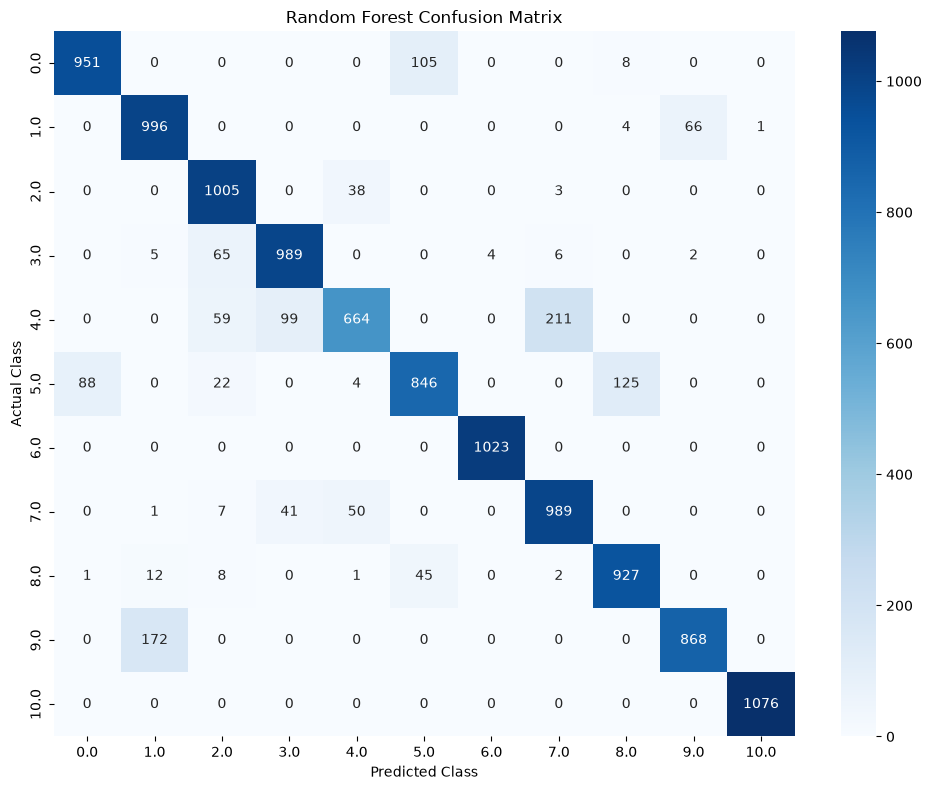

In [30]:
rf_confusion = (
    rf_predictions
    .groupBy("label", "prediction")
    .count()
    .orderBy("label", "prediction")
)

confusion_pd = (
    rf_confusion
    .toPandas()
    .pivot(
        index="label",
        columns="prediction",
        values="count"
    )
    .fillna(0)
)

plt.figure(figsize=(10, 8))
sns.heatmap(
    confusion_pd,
    annot=True,
    fmt=".0f",
    cmap="Blues"
)
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

In [31]:
# Calculate recall for each actual class.
class_recall = (
    rf_predictions
    .groupBy("label")
    .agg(
        count("*").alias("total"),
        count(when(col("label") == col("prediction"), True))
        .alias("correct")
    )
    .withColumn(
        "recall",
        col("correct") / col("total")
    )
    .orderBy("label")
)

class_recall.show(11)

+-----+-----+-------+------------------+
|label|total|correct|            recall|
+-----+-----+-------+------------------+
|  0.0| 1064|    951| 0.893796992481203|
|  1.0| 1067|    996|0.9334582942830365|
|  2.0| 1046|   1005|0.9608030592734226|
|  3.0| 1071|    989|   0.9234360410831|
|  4.0| 1033|    664|0.6427879961277831|
|  5.0| 1085|    846|0.7797235023041474|
|  6.0| 1023|   1023|               1.0|
|  7.0| 1088|    989|0.9090073529411765|
|  8.0|  996|    927|0.9307228915662651|
|  9.0| 1040|    868|0.8346153846153846|
| 10.0| 1076|   1076|               1.0|
+-----+-----+-------+------------------+



In [32]:
# Show the most common incorrect class predictions.
error_patterns = (
    rf_predictions
    .filter(col("label") != col("prediction"))
    .groupBy("label", "prediction")
    .count()
    .orderBy(col("count").desc())
)

error_patterns.show(10)

+-----+----------+-----+
|label|prediction|count|
+-----+----------+-----+
|  4.0|       7.0|  211|
|  9.0|       1.0|  172|
|  5.0|       8.0|  125|
|  0.0|       5.0|  105|
|  4.0|       3.0|   99|
|  5.0|       0.0|   88|
|  1.0|       9.0|   66|
|  3.0|       2.0|   65|
|  4.0|       2.0|   59|
|  7.0|       4.0|   50|
+-----+----------+-----+
only showing top 10 rows


The confusion matrix and per-class recall provide more detail than overall accuracy. The most frequent incorrect class pairs show which operating conditions the model has difficulty separating. In a real manufacturing environment, these errors should be reviewed with domain experts because confusing two conditions may have different maintenance consequences.

## Feature Importance

Random Forest feature importance is used to identify which sensor features contributed most to the model. This can help the maintenance team understand which measurements are most useful for distinguishing operating conditions. Feature importance indicates predictive contribution, not a causal relationship.

       Feature  Importance
10  feature_11    0.181887
9   feature_10    0.176458
7   feature_08    0.134055
8   feature_09    0.122356
11  feature_12    0.115271
6   feature_07    0.094114
35  feature_36    0.023739
33  feature_34    0.017064
24  feature_25    0.016532
27  feature_28    0.014738


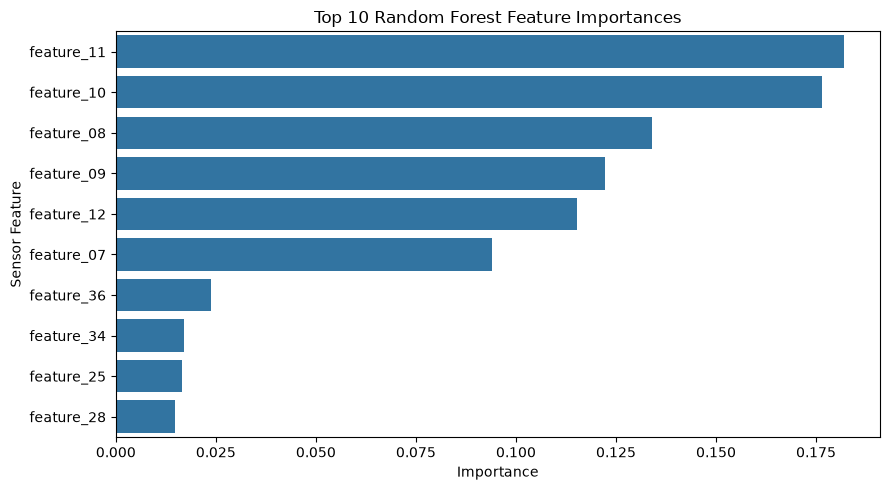

In [34]:
# Get the trained Random Forest model.
best_rf = best_rf_model.stages[-1]

# Get feature importance values.
importance_values = best_rf.featureImportances.toArray()

# Create a DataFrame with feature names and importance scores.
importance_pd = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": importance_values
})

# Sort features by importance.
importance_pd = importance_pd.sort_values(
    "Importance",
    ascending=False
)

# Display the top 10 features.
print(importance_pd.head(10))

# Plot the top 10 features.
plt.figure(figsize=(9, 5))

sns.barplot(
    data=importance_pd.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Sensor Feature")
plt.tight_layout()
plt.show()

The feature importance results identify the sensor measurements that contributed most to the Random Forest predictions. These features may be useful candidates for additional monitoring and investigation. However, feature importance should be interpreted as a model-based measure rather than proof that a particular sensor directly causes an operating condition.

In [35]:
# Compare the two models using the same evaluation metrics.
print("Model comparison:")
print(results_pd.round(4).to_string(index=False))

print("\nTraining times:")
print("Logistic Regression:", round(logistic_training_time, 2), "seconds")
print("Random Forest tuning:", round(rf_training_time, 2), "seconds")

Model comparison:
              Model  accuracy     f1  weightedPrecision  weightedRecall
Logistic Regression    0.8003 0.7940             0.7996          0.8003
      Random Forest    0.8917 0.8896             0.8932          0.8917

Training times:
Logistic Regression: 4.77 seconds
Random Forest tuning: 3.18 seconds


## Model Comparison Interpretation

Random Forest outperformed Logistic Regression on all four metrics. With an improvement in accuracy of 0.8003 to 0.8917 and improvement in weighted F1 score of 0.7940 to 0.8896. In terms of training time Random Forest was faster in this instance at 3.18 seconds compared with Logistic Regression taking 4.77 seconds. However, training times can vary depending on the data, hardware and model settings. Due to Random Forest having higher predictive performance, this model is a better choice for this dataset.

## Reproducibility

The split of train and test set, the Random Forest model and the hyperparameter tuning step use the same seed value of 42. The source of the dataset and the names of the features are noted along with the pre-processing steps, model parameters and Spark details. The pre-processing and classification steps are written as pipelines in Spark ML to ensure they can be applied in the same order when training again in the future. In a production pipeline we would also want to note the version of the dataset, date trained, version of Spark, Python, chosen model parameters, metrics and where the model artefact is saved. This will help us to recreate our results and compare different versions of our model in the future.

## Monitoring and Drift Detection

After deployment, you will need to monitor the number of predictions being made, the prediction time, any failed predictions, how many missing values there are from each sensor and what the predicted operating conditions are distributed like. You should check that the features within the predictions are distributed similarly to those in the training data. This is to make sure that there has not been any drift in the data. If there has been a change in how often different operating conditions are being predicted it may be due to a genuine change in the behaviour of the equipment or maybe there has been a change in the way the data was collected. Once the labelled data becomes available (from maintenance inspections) the team should monitor the accuracy, weighted f1 score and recall for each class. If there is a drop in performance for any of the operating conditions it should be looked into. Large changes in feature distributions, missing data, failed predictions and consistent drops in model performance should trigger alerts.

## Computational Cost and Deployment

Logistic Regression can be a great choice when looking to reduce training times, keep things simple and reduce resources used. Random Forest will add extra compute time due to building many Decision Trees and trying different parameter combinations. This can be run during periodic retraining sessions. The Spark pipeline can be run locally and then deployed into a cluster for larger retraining jobs. When running on a cluster you would take note of the Executor memory, CPU and Shuffle usage, alongside training times. This will give us an initial indication of how it would work however we would need to measure how it actually performs on a cluster.

## Rollback Plan

Once a valid version of the model has been validated it should be saved with its pre-processing, configuration and evaluation. When a new model is being introduced it should only be used in production when it has passed validation and performed well on a separate test dataset. If a new model has caused a continuous increase in classification error, unpredictable results or operational issues like high latency, the system should revert to the last valid model. The last valid model should be available until the new model has been monitored. This ensures that the team can revert to a known working model without needing to retrain.

## Final Recommendation

Overall, Random Forest was the better model since it improved upon Logistic Regression in the test set. This can be seen by how it improved weighted F1 scores and class recalls. The non-linear nature of Random Forest makes it suitable for diagnosing conditions using sensors. It does require more resources when training and more hyperparameter tuning. Logistic Regression was still useful to use as a baseline due to being simpler and requiring less computation. If Random Forest improves sufficiently to justify the added cost of using it and class errors are acceptable to the maintenance team then I would deploy this model. The model should be run on newer sensor data to ensure it is still performing well, and monitored to check there are no shifts in the distribution of features.

## Conclusion

This assignment used PySpark to create a scalable multi-class classification model for Sensorless Drive Diagnosis. The data was loaded and validated using guardrail rules. Class balance, summary statistics, feature distribution and correlations were identified. A pre-processing pipeline was created using the 48 sensor features. A baseline model was created using Logistic Regression but the Random Forest model was tuned for better comparison. The models were compared using the metrics from the holdout set and diagnostic plots. This experiment was also considered for its replicability, monitoring, drifting, computational expense and rollback capabilities. The results give a good foundation for creating a larger predictive maintenance workflow within Spark. Further testing would have been required using real production sensor data.

In [36]:
spark.stop()
print("Spark session stopped.")

Spark session stopped.
